# Assignment 5: Convolutional Variational Autoencoder (CVAE) on MNIST
**Author:** Kristian Hudák  
**Course:** AI Olympiad (OAI) Preparation Course

This notebook demonstrates latent space exploration and generative reconstruction using a Convolutional Variational Autoencoder (CVAE) trained on MNIST:
- Image compression into an ultra-compact 2D continuous latent space ($z \in \mathbb{R}^2$)
- 2D scatter visualization of digit class clusters (butterfly manifold structure)
- Smooth generative grid manifold sampling (20x20 interpolated digit reconstruction)


In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchsummary import summary


In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)


cuda


In [4]:
# the champion in image compression into low-dimensional features is the convolutional variational autoencoder
# it can encode images from the MNIST dataset into just two features.
# download variational autoencoder
!wget http://agentspace.org/download/mnist_cvae_encoder.pth
!wget http://agentspace.org/download/mnist_cvae_decoder.pth


--2025-11-16 18:02:00--  http://agentspace.org/download/mnist_cvae_encoder.pth
Resolving agentspace.org (agentspace.org)... 62.168.101.9
Connecting to agentspace.org (agentspace.org)|62.168.101.9|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://www.agentspace.org/download/mnist_cvae_encoder.pth [following]
--2025-11-16 18:02:01--  https://www.agentspace.org/download/mnist_cvae_encoder.pth
Resolving www.agentspace.org (www.agentspace.org)... 62.168.101.9
Connecting to www.agentspace.org (www.agentspace.org)|62.168.101.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 350979 (343K)
Saving to: ‘mnist_cvae_encoder.pth’

mnist_cvae_encoder. 100%[===================>] 342.75K   495KB/s    in 0.7s    

2025-11-16 18:02:04 (495 KB/s) - ‘mnist_cvae_encoder.pth’ saved [350979/350979]

--2025-11-16 18:02:04--  http://agentspace.org/download/mnist_cvae_decoder.pth
Resolving agentspace.org (agentspace.org)... 62.168.101.9
Co

In [5]:
# load variational autoencoder
encoder = torch.load('mnist_cvae_encoder.pth', weights_only=False, map_location=device)
decoder = torch.load('mnist_cvae_decoder.pth', weights_only=False, map_location=device)


In [6]:
encoder.eval()


Sequential(
  (0): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU()
    (7): Conv2d(32, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (8): ReLU()
    (9): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU()
    (14): Flatten(start_dim=1, end_dim=-1)
    (15): Linear(in_features=3136, out_features=4, bias=True)
  )
  (1): Linear(in_features=4, out_features=2, bias=False)
)

In [7]:
decoder.eval()


Sequential(
  (0): Linear(in_features=2, out_features=1568, bias=True)
  (1): ReLU()
  (2): Unflatten(dim=1, unflattened_size=(32, 7, 7))
  (3): ConvTranspose2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): ConvTranspose2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (6): ReLU()
  (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (8): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): ReLU()
  (10): ConvTranspose2d(32, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (11): ReLU()
  (12): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ConvTranspose2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (14): Sigmoid()
)

In [8]:
# test dataloader
batch_size = 256
test_loader = DataLoader(datasets.MNIST(root='data', train=False, download=True, transform=transforms.ToTensor()), batch_size=batch_size, shuffle=False)


100%|██████████| 9.91M/9.91M [00:00<00:00, 19.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 485kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.00MB/s]


In [9]:
# get few samples
test_iter = iter(test_loader)
x_sample = next(test_iter)[0][0:10].to(device)
print(x_sample.shape)


torch.Size([10, 1, 28, 28])


In [10]:
# encode and decode
y_sample = decoder(encoder(x_sample))
print(y_sample.shape)


torch.Size([10, 1, 28, 28])


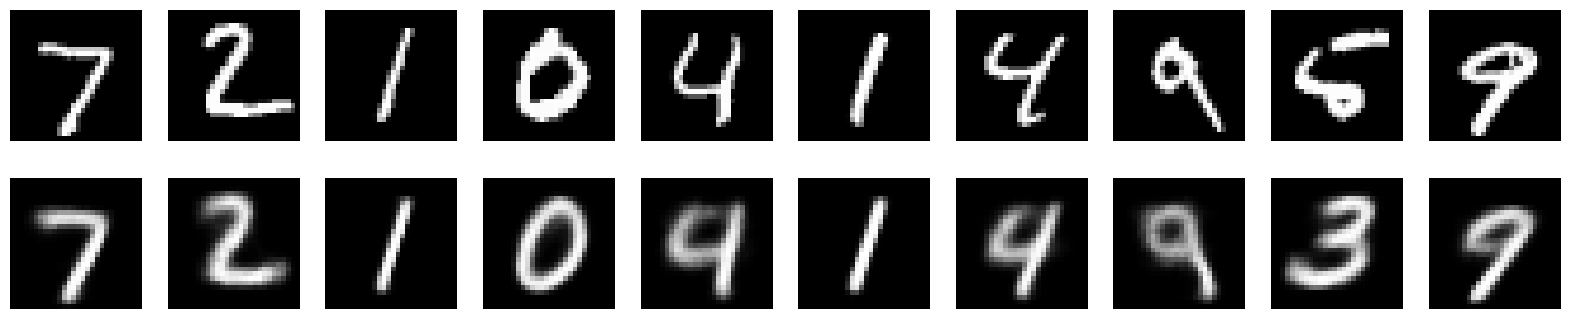

In [11]:
# show the comparison
plt.figure(figsize=(20, 4))
for i in range(10):
    input_img = (x_sample[i].squeeze(0).detach().cpu().numpy()*255).astype(np.uint8)
    plt.subplot(2, 10, i+1)
    plt.imshow(input_img, cmap='gray')
    plt.axis('off')
    output_img = (y_sample[i].squeeze(0).detach().cpu().numpy()*255).astype(np.uint8)
    plt.subplot(2, 10, i+1+10)
    plt.imshow(output_img, cmap='gray')
    plt.axis('off')
plt.show()


In [12]:
feature_vectors = []
categories = []
for batch, (x_test, y_test) in enumerate(test_loader):
    feature_vector = encoder(x_test.to(device))
    feature_vectors.append(feature_vector)
    categories += [ category.item() for category in y_test ]
feature_vectors = torch.cat(feature_vectors, dim=0)
print(feature_vectors.shape)


torch.Size([10000, 2])


In [13]:
print(feature_vectors[0:10])


tensor([[ 1.0535,  0.4682],
        [-1.2919,  0.5398],
        [ 1.2825, -1.4180],
        [-1.4679, -1.4997],
        [ 0.6535,  1.7880],
        [ 1.1910, -1.3367],
        [ 0.6310,  0.8953],
        [-0.0436,  1.7765],
        [-0.5829,  0.2229],
        [ 0.3830, -0.0824]], device='cuda:0', grad_fn=<SliceBackward0>)


In [14]:
categories[0:10]


[7, 2, 1, 0, 4, 1, 4, 9, 5, 9]

In [15]:
points = feature_vectors.detach().cpu().numpy()
print(points.shape)


(10000, 2)


In [16]:
colors = { 0 : (0,0,255), 1 : (0,255,255), 2 : (0,255,0), 3 : (255,255,0), 4 : (255,255,255), 5: (160,160,160), 6: (255,0,0), 7: (255,0,255), 8: (80,80,0), 9 : (80,0,0) }


In [24]:
def display(points,types):
    latent_range = 1.6
    points = (points + latent_range) / (2 * latent_range)
    v = 800
    graph = np.zeros((v,v,3),np.uint8)
    for i in range(len(points)):
        cv2.circle(graph,(int(v*points[i,0]),int(v*(1-points[i,1]))),2,colors[types[i]],cv2.FILLED)

    for j in range(10):
        cv2.rectangle(graph,(j*32,0),((j+1)*32,32),colors[j],cv2.FILLED)
        cv2.putText(graph,str(j),(j*32+8,32-8),0,0.9,(0,0,0))

    return graph


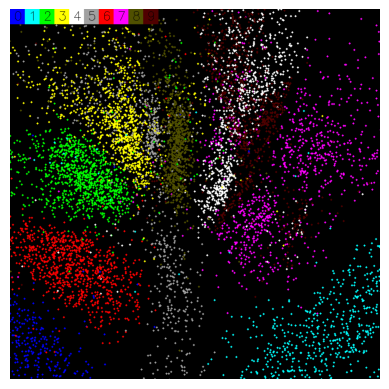

In [25]:
graph = display(points,categories)
cv2.imwrite('latent-space(motyl).png',graph)
plt.imshow(graph)
plt.axis('off')
plt.show()


### Task 1: 2D Latent Space Projection of MNIST Test Dataset

Visualizing the test dataset projected into the 2D continuous latent space:

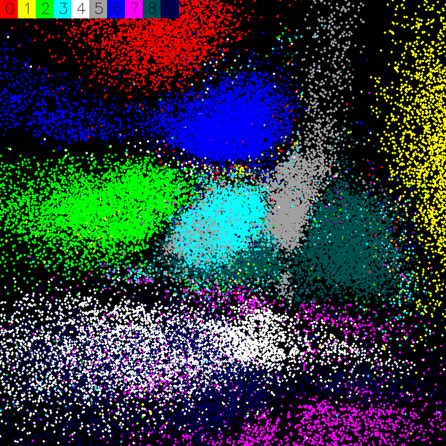

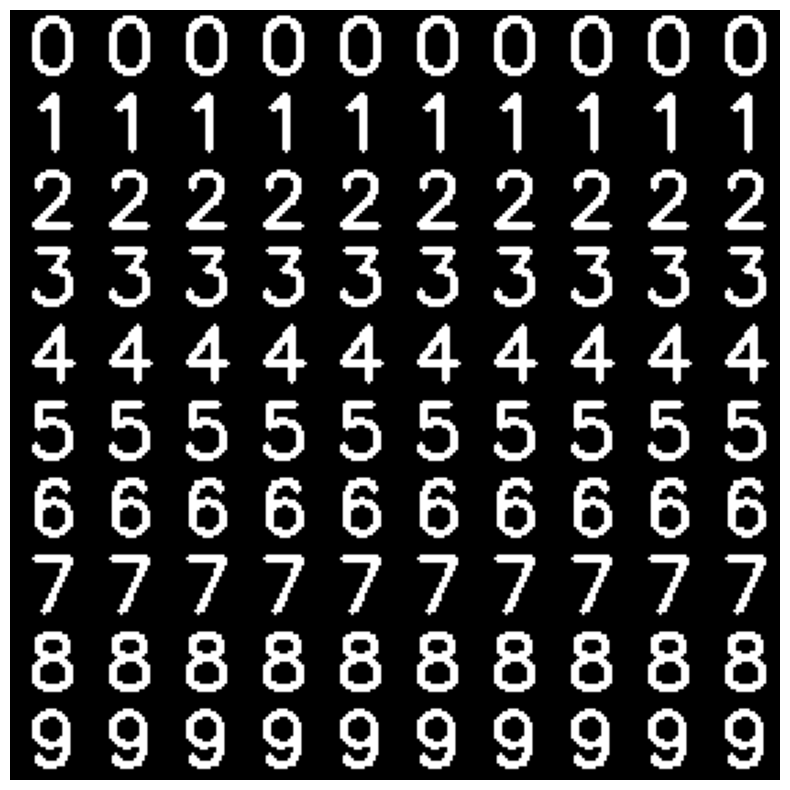

In [30]:
# How to put rendered images on the common background
def render(digit):
    img = np.zeros((28, 28), dtype=np.uint8)
    cv2.putText(img, str(digit), (6, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.9, 255, 2)
    return img

# Create a grid image: 10 rows (digits 0–9), each row with 10 copies of the same digit
rows = []
for digit in range(10):
    row = np.hstack([render(digit) for _ in range(10)])  # 10 copies horizontally
    rows.append(row)

grid_img = np.vstack(rows)  # stack all rows vertically

plt.figure(figsize=(10, 10))
plt.imshow(grid_img, cmap='gray')
plt.axis('off')
plt.show()


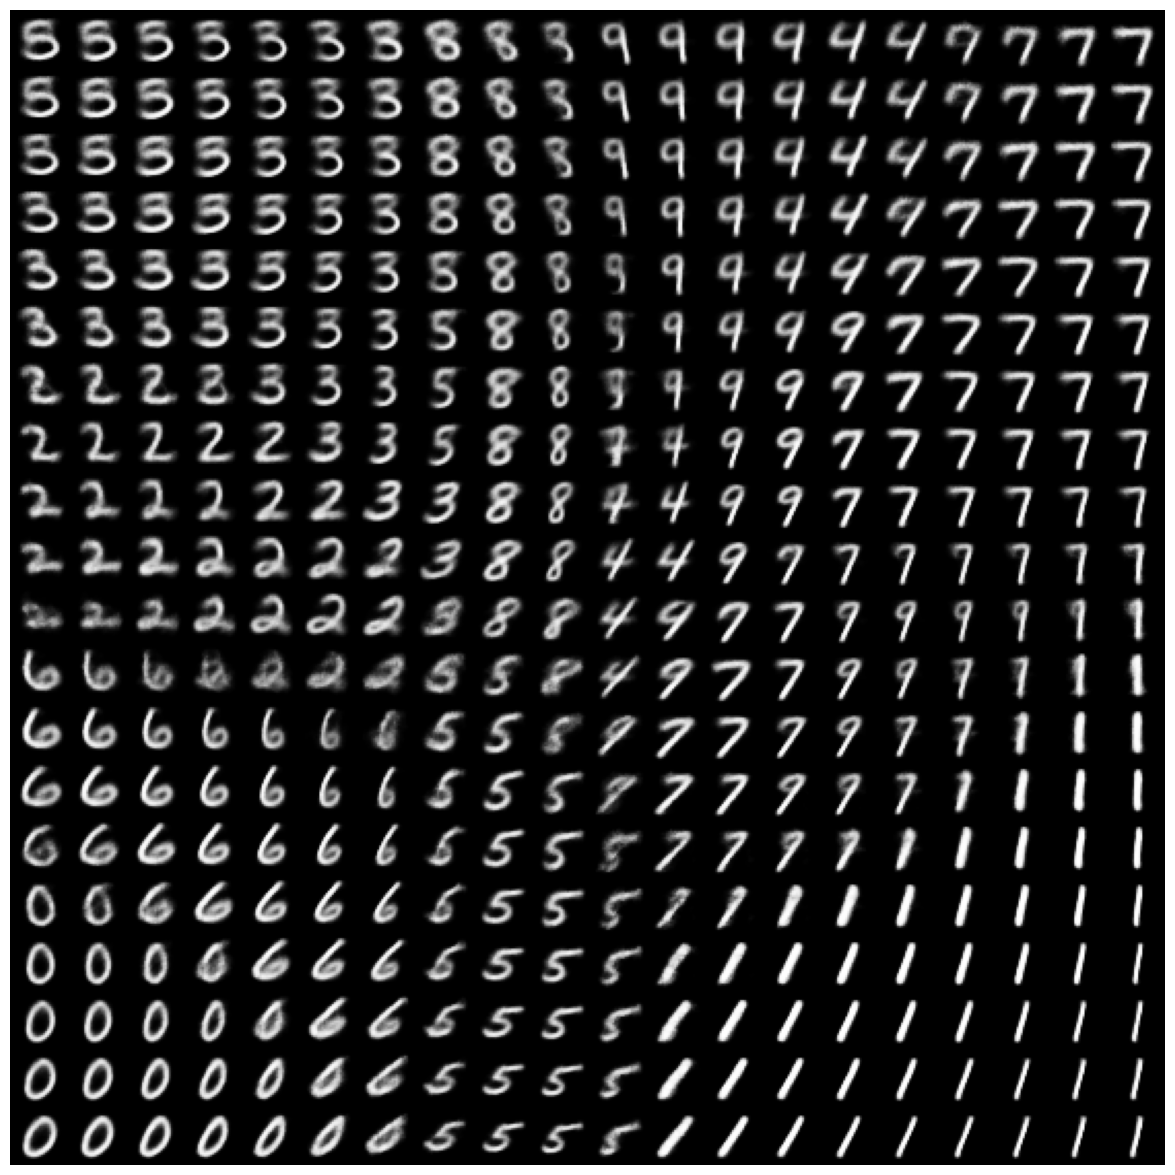

In [34]:
velkost = 20  # backwards compatibility
grid_size = 20 # 20x20 grid

latent_range = 1.6

grid_x = np.linspace(-latent_range, latent_range, velkost)
grid_y = np.linspace(-latent_range, latent_range, velkost)

generovane = []
for yi in grid_y[::-1]:   # Y os prevrátená
    for xi in grid_x:
        stvorcek = torch.tensor([[xi, yi]], dtype=torch.float32).to(device)
        with torch.no_grad():
            decoded_img = decoder(stvorcek).cpu()
        generovane.append(decoded_img.squeeze().numpy())


rows1 = []
for i in range(velkost):
    row_images = generovane[i * velkost : (i + 1) * velkost]
    rows1.append(np.hstack(row_images))

final_grid_image = np.vstack(rows1)

plt.figure(figsize=(15, 15))
plt.imshow(final_grid_image, cmap='gray')
plt.axis('off')
plt.show()



### Task 2: Generative Manifold Sampling Across Latent Space

Visualizing digits generated across a uniform 2D grid in the latent space:

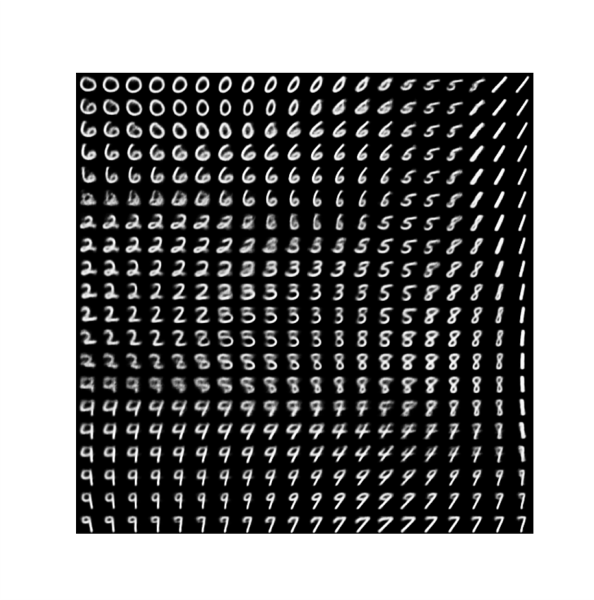